# Monitor de medios argentinos · análisis de la base

Notebook de respaldo para la clase: reproduce los análisis principales del tablero con **SQL + pandas**.
Usa la base local (`historico.db`) si existe; si no, baja la publicada en GitHub Pages.

- Tablero: https://miguegarrone-blip.github.io/Web-Mining/
- Requisitos: `pip install pandas matplotlib`

In [1]:
import os, sqlite3, urllib.request
import pandas as pd
import matplotlib.pyplot as plt

URL = "https://miguegarrone-blip.github.io/Web-Mining/historico.db"
DB = "historico.db"
if not os.path.exists(DB):
    urllib.request.urlretrieve(URL, DB)
con = sqlite3.connect(DB)
sql = lambda q: pd.read_sql_query(q, con)

AZUL, ROJO, VERDE, GRIS = "#1F5F8B", "#B5483A", "#3D8A5A", "#9AA29C"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})
TONO = "COALESCE(NULLIF(tono_manual,''), tono_auto)"

## 1. Panorama de la base

In [2]:
sql(f'''
SELECT COUNT(*) AS notas, COUNT(DISTINCT medio) AS medios,
       DATE(MIN(pub_ms)/1000, 'unixepoch', '-3 hours') AS desde,
       DATE(MAX(pub_ms)/1000, 'unixepoch', '-3 hours') AS hasta,
       ROUND(100.0*AVG(bajada != ''), 1) AS pct_con_bajada,
       ROUND(100.0*AVG(ld = 1), 1) AS pct_con_json_ld,
       ROUND(100.0*AVG(bert_t IS NOT NULL), 1) AS pct_tono_bert
FROM items WHERE pub_ms > 0''')

,notas,medios,desde,hasta,pct_con_bajada,pct_con_json_ld,pct_tono_bert
0,5093,45,2020-06-04,2026-10-24,95.5,95.9,100.0


Tablas de la base y su tamaño:

In [3]:
sql("SELECT name AS tabla FROM sqlite_master WHERE type='table'").assign(
    filas=lambda d: [sql(f"SELECT COUNT(*) n FROM {t}").n[0] for t in d.tabla])

,tabla,filas
0,items,5093
1,salud,460
2,cuarentena,1315
3,meta,2
4,scraping,275


## 2. Tono por medio
Porcentaje de notas negativas y positivas según el modelo combinado (palabras + XLM-RoBERTa).

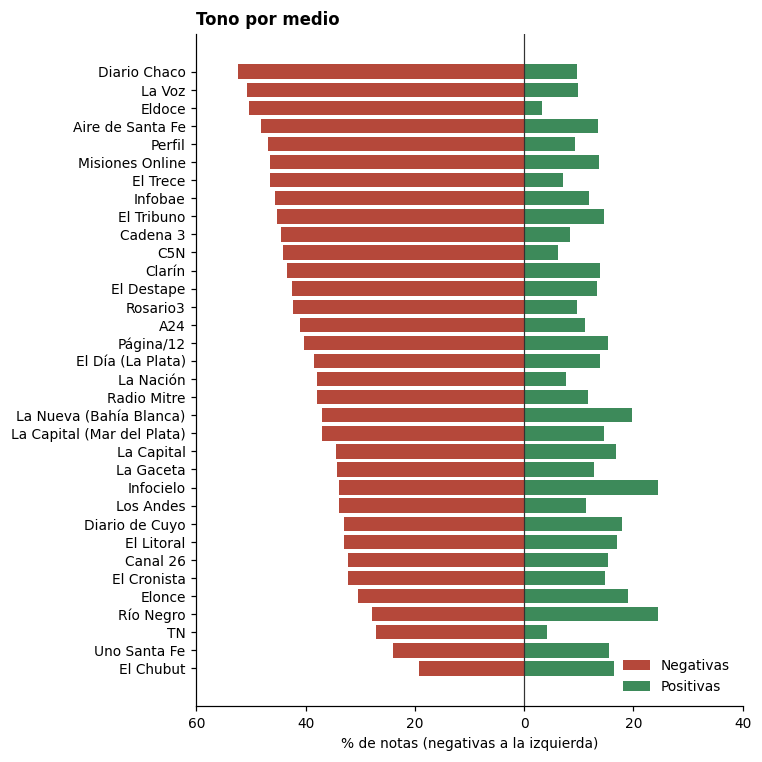

In [4]:
t = sql(f'''
SELECT medio, COUNT(*) AS notas,
       100.0*AVG({TONO}='n') AS negativas, 100.0*AVG({TONO}='p') AS positivas
FROM items GROUP BY medio HAVING notas >= 60 ORDER BY negativas''')
fig, ax = plt.subplots(figsize=(7, 7))
ax.barh(t.medio, -t.negativas, color=ROJO, label="Negativas")
ax.barh(t.medio, t.positivas, color=VERDE, label="Positivas")
ax.axvline(0, color="#333", lw=.8); ax.set_xlabel("% de notas (negativas a la izquierda)")
ax.set_xticks(range(-60, 41, 20)); ax.set_xticklabels([abs(x) for x in range(-60, 41, 20)])
ax.legend(loc="lower right", frameon=False); ax.set_title("Tono por medio", loc="left", fontweight="bold")
plt.tight_layout(); plt.show()

## 3. Agenda de cada medio
Qué parte de sus notas dedica cada medio a cada tema, comparado con el promedio (más oscuro = más que el promedio).

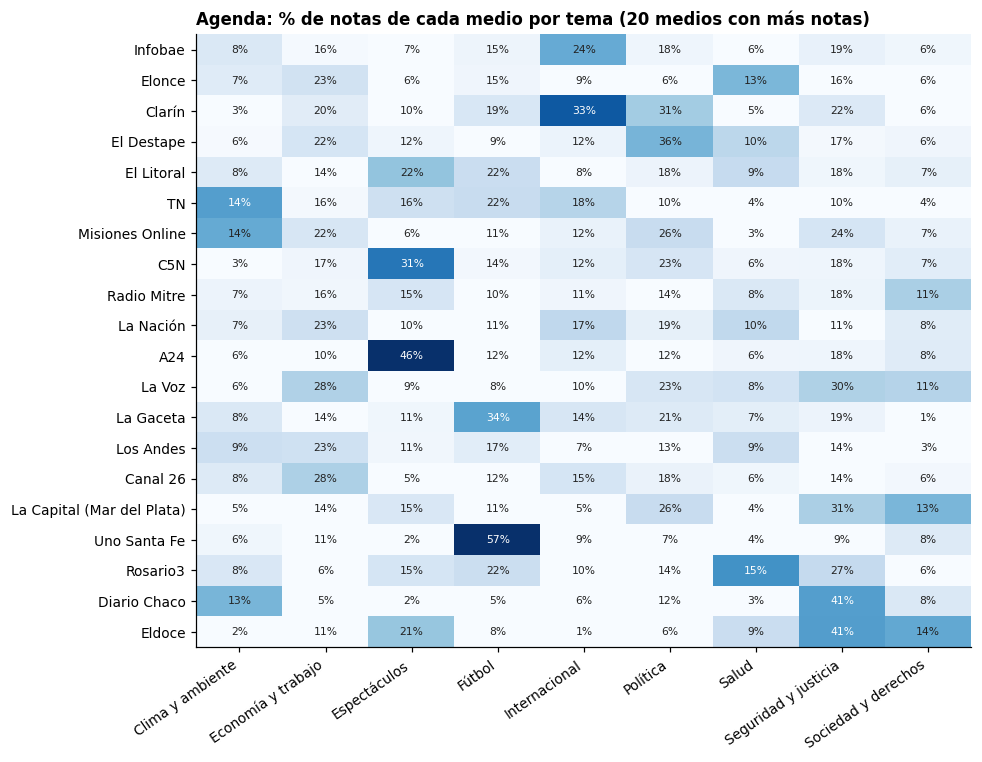

In [5]:
it = sql("SELECT medio, temas FROM items")
it["tema"] = it.temas.str.split("|"); it = it.explode("tema")
top = it[it.tema != "Otros"].tema.value_counts().head(9).index
notas = sql("SELECT medio, COUNT(*) n FROM items GROUP BY medio").set_index("medio").n
tab = it[it.tema.isin(top)].groupby(["medio", "tema"]).size().unstack(fill_value=0)
tab = tab.loc[notas[notas >= 60].index.intersection(tab.index)]
share = tab.div(notas[tab.index], axis=0)
ratio = share / (tab.sum() / notas[tab.index].sum())
share = share.loc[notas[share.index].sort_values(ascending=False).index[:20]]; ratio = ratio.loc[share.index]
fig, ax = plt.subplots(figsize=(9, 7))
ax.imshow(ratio.clip(0, 3).values, cmap="Blues", vmin=0.8, vmax=3, aspect="auto")
ax.set_xticks(range(len(share.columns))); ax.set_xticklabels(share.columns, rotation=35, ha="right")
ax.set_yticks(range(len(share.index))); ax.set_yticklabels(share.index)
for i in range(share.shape[0]):
    for j in range(share.shape[1]):
        ax.text(j, i, f"{share.iat[i, j]*100:.0f}%", ha="center", va="center", fontsize=7, color="white" if ratio.iat[i, j] > 2 else "#222")
ax.set_title("Agenda: % de notas de cada medio por tema (20 medios con más notas)", loc="left", fontweight="bold")
plt.tight_layout(); plt.show()

## 4. Cómo titula cada medio
**Cebo**: títulos con preguntas, exclamaciones, adjetivos exagerados, intriga, segunda persona o listas. **Exageración**: títulos negativos cuya bajada (escrita por el propio medio) no es negativa.

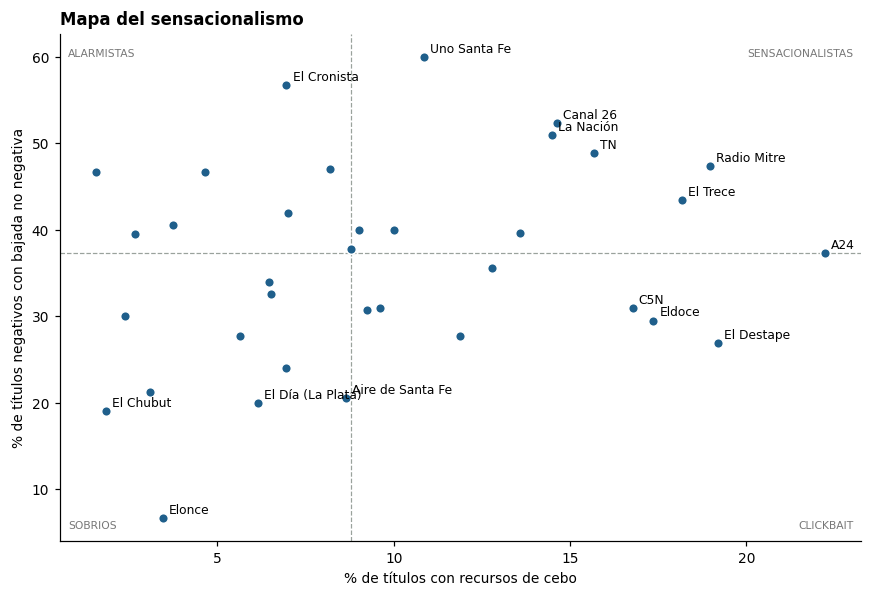

In [6]:
s = sql(f'''
SELECT medio,
       100.0*AVG(cebo >= 1) AS cebo,
       100.0*SUM(tono_bajada IS NOT NULL AND {TONO}='n' AND tono_bajada != 'n')
            / SUM(tono_bajada IS NOT NULL AND {TONO}='n') AS exagera,
       SUM(tono_bajada IS NOT NULL AND {TONO}='n') AS base
FROM items GROUP BY medio HAVING base >= 15 AND COUNT(*) >= 40''')
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.scatter(s.cebo, s.exagera, s=40, color=AZUL, edgecolor="white", zorder=3)
mx, my = s.cebo.median(), s.exagera.median()
ax.axvline(mx, ls="--", color=GRIS, lw=.8); ax.axhline(my, ls="--", color=GRIS, lw=.8)
for _, r in s.iterrows():
    if r.cebo > s.cebo.quantile(.8) or r.exagera > s.exagera.quantile(.85) or r.exagera < s.exagera.quantile(.1):
        ax.annotate(r.medio, (r.cebo, r.exagera), xytext=(4, 3), textcoords="offset points", fontsize=8)
for x, y, t, ha in [(.01, .97, "ALARMISTAS", "left"), (.99, .97, "SENSACIONALISTAS", "right"), (.01, .02, "SOBRIOS", "left"), (.99, .02, "CLICKBAIT", "right")]:
    ax.text(x, y, t, transform=ax.transAxes, ha=ha, va="top" if y > .5 else "bottom", fontsize=7, color="#777")
ax.set_xlabel("% de títulos con recursos de cebo"); ax.set_ylabel("% de títulos negativos con bajada no negativa")
ax.set_title("Mapa del sensacionalismo", loc="left", fontweight="bold"); plt.tight_layout(); plt.show()

## 5. Transparencia: notas firmadas por un periodista
Según el autor que declara cada medio en el JSON-LD de la nota.

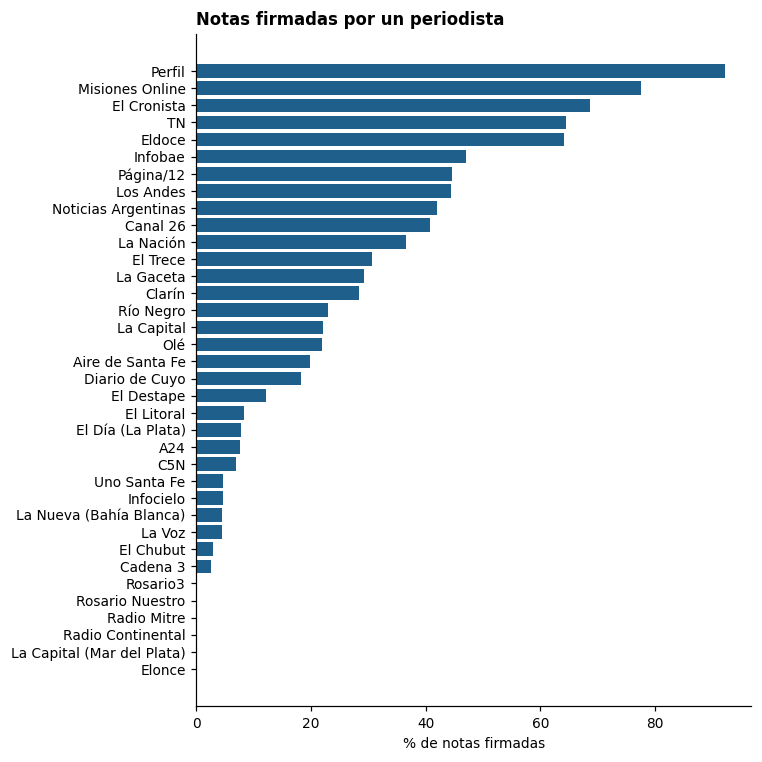

In [7]:
f = sql('''SELECT medio, 100.0*SUM(firmada=1)/SUM(ld=1) AS firmadas, SUM(ld=1) AS con_json_ld
FROM items GROUP BY medio HAVING con_json_ld >= 40 ORDER BY firmadas''')
fig, ax = plt.subplots(figsize=(7, 7))
ax.barh(f.medio, f.firmadas, color=AZUL); ax.set_xlabel("% de notas firmadas")
ax.set_title("Notas firmadas por un periodista", loc="left", fontweight="bold"); plt.tight_layout(); plt.show()

Periodistas con más notas:

In [8]:
sql(f'''SELECT autor, medio, COUNT(*) AS notas, ROUND(100.0*AVG({TONO}='n'),0) AS pct_negativas
FROM items WHERE firmada=1 GROUP BY autor, medio ORDER BY notas DESC LIMIT 10''')

,autor,medio,notas,pct_negativas
0,Karina Gonzalez,Misiones Online,37,65.0
1,Agustina Alvarez,Eldoce,19,74.0
2,Manuel Luna,Eldoce,17,53.0
3,Andrés Ñáñez,Eldoce,15,87.0
4,Nuria Dos Santos,Misiones Online,14,14.0
5,Ariel Sánchez,Perfil,13,62.0
6,Griselda Segovia,Misiones Online,13,62.0
7,Juliana Morales,Eldoce,13,54.0
8,Ezequiel Alippe,Canal 26,12,50.0
9,Ivan Rippel,Misiones Online,10,20.0


## 6. Cómo trata cada medio a cada figura
% de notas negativas por medio cuando menciona a cada figura (celdas con 3 notas o más).

In [9]:
e = sql(f"SELECT medio, entidades, {TONO}='n' AS neg FROM items WHERE entidades != ''")
e["figura"] = e.entidades.str.split("|"); e = e.explode("figura")
figs = e.figura.value_counts().head(6).index
g = e[e.figura.isin(figs)].groupby(["medio", "figura"]).neg.agg(["mean", "size"])
piv = g["mean"].where(g["size"] >= 3).unstack()[figs].dropna(how="all")
(piv*100).round(0).sort_index().style.background_gradient(cmap="Reds", vmin=0, vmax=100).format("{:.0f}", na_rep="·")

figura,Javier Milei,Lionel Messi,Papa León XIV,Policía,Boca,Donald Trump
medio,,,,,,
A24,40,33,17,100,0,·
Aire de Santa Fe,·,·,·,100,·,·
C5N,33,0,50,·,·,·
Cadena 3,80,0,·,·,·,·
Canal 26,40,·,50,·,·,·
Clarín,36,0,·,·,·,72
Diario Chaco,40,·,·,75,·,·
Diario de Cuyo,25,·,67,·,·,·
El Chubut,·,·,·,75,·,·


## 7. Evolución diaria
Notas por día y % negativo (por fecha de publicación, hora argentina).

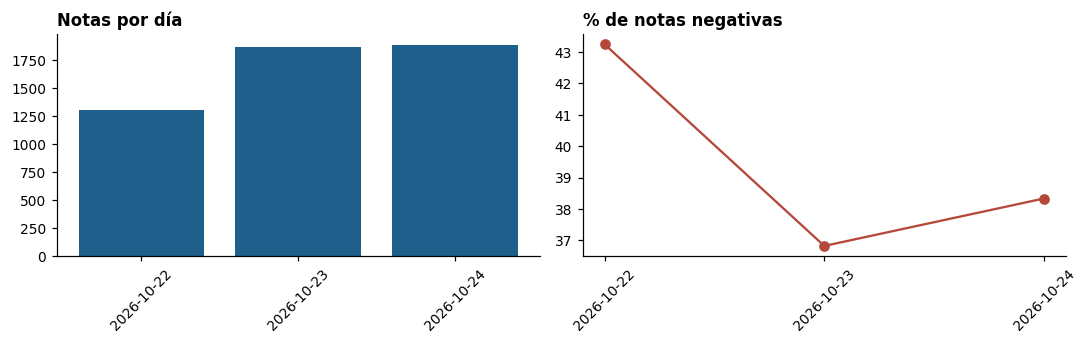

In [10]:
d = sql(f'''SELECT DATE(pub_ms/1000, 'unixepoch', '-3 hours') AS dia, COUNT(*) AS notas, 100.0*AVG({TONO}='n') AS negativas
FROM items WHERE pub_ms > 0 GROUP BY dia HAVING notas >= 50 ORDER BY dia''')
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].bar(d.dia, d.notas, color=AZUL); ax[0].set_title("Notas por día", loc="left", fontweight="bold")
ax[1].plot(d.dia, d.negativas, color=ROJO, marker="o"); ax[1].set_title("% de notas negativas", loc="left", fontweight="bold")
for a in ax: a.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

## 8. Consulta libre
Cualquier consulta SQL sobre la base. Por ejemplo, los títulos negativos cuya bajada es neutra (casos de exageración):

In [11]:
sql(f'''SELECT medio, titulo, bajada FROM items
WHERE {TONO}='n' AND tono_bajada='0' AND cebo >= 1
ORDER BY pub_ms DESC LIMIT 10''')

,medio,titulo,bajada
0,TN,Qué hacer durante los primeros 10 minutos desp...,"Lo primero es ponerse a salvo, intentar pensar..."
1,La Nación,Polémica por otra novela premiada por un prest...,"Según un informe del diario “El País”, la nove..."
2,La Nación,Por qué aparecen ciempiés en casa y qué intent...,"Aunque su apariencia puede generar rechazo, es..."
3,La Nación,Pedro Luis Barcia. “Padecemos sisifismo: subim...,"El erudito, que recibirá este lunes la distinc..."
4,Infobae,Iván Cepeda cuestionó las afirmaciones del vic...,El senador del Pacto Histórico recordó que el ...
5,Radio Mitre,Una nena cayó desde la ventana de un segundo p...,"El hecho ocurrió en Delmiro Gouveia, Brasil. U..."
6,La Nación,"Jerry Klein, veterinario: “Cambiar de tipo o m...",El especialista del American Kennel Club expli...
7,TN,Una nena cayó por la ventana de un segundo pis...,Un policía subió por una ventana y logró poner...
8,Rosario3,Cuáles son los siete errores cotidianos que ex...,Un informe brasilero difundió recomendaciones ...
9,Noticias Argentinas,Mito vs. Realidad: ¿Por qué Lula afirmó que lo...,Qué dicen los datos duros sobre el consumo de ...
